# TP1 — Optimisation continue et linéaire

**Séance 1 — Optimisation pour l'IA — MS IA de Confiance, CentraleSupélec**

Dans ce TP vous allez, **étape par étape** :

1. Implémenter la **descente de gradient** à partir de zéro et étudier l'effet du pas.
2. Implémenter et comparer une méthode **accélérée (momentum / Nesterov)**.
3. Résoudre un **problème continu contraint** avec une méthode de barrière, `scipy.optimize`, et `cvxpy`.
4. Formuler et résoudre un **programme linéaire** avec `scipy.optimize.linprog` et `PuLP`, et le comparer à votre résolution du simplexe à la main faite en TD.
5. Démarrer votre **projet individuel ExedBike (Partie 1)**.

**Comment ce notebook est organisé.** Chaque exercice est découpé en petites étapes : une cellule **`# A COMPLETER`** à écrire, suivie presque toujours d'une cellule **de vérification** (marquée ✅) qui teste automatiquement votre code et vous dit si c'est correct — lancez les cellules **dans l'ordre**, une par une, et ne passez à la suivante que lorsque la vérification est au vert. Aucune solution n'est donnée à l'avance : le but est que chaque ligne que vous exécutez, vous l'ayez écrite (ou complétée) vous-même.

Bibliothèques nécessaires : `numpy`, `matplotlib`, `autograd`, `scipy`, `cvxpy`, `pulp`.

> **Environnement et noyau.** Ouvrir ce notebook avec un noyau Python 3.12 disposant des bibliothèques ci-dessous. La commande suivante, à lancer dans le terminal de cet environnement, installe les versions utilisées pour les résultats enregistrés :

```sh
python -m pip install numpy==2.5.4 scipy==1.18.1 matplotlib==3.11.2 autograd==1.9.1 cvxpy==1.9.3 pulp==3.3.2 ipykernel==7.4.0
```

La première cellule contrôle la présence des bibliothèques et la compatibilité de PuLP. Après une installation, sélectionner ce noyau puis le redémarrer. Exécuter les cellules dans l’ordre depuis le dossier `TP1` ou la racine du dépôt ; les fichiers `generate_instance.py` et `large.dzn` fournis sont utilisés par l’exploration facultative.

In [1]:
import sys
import importlib.util
from importlib.metadata import version

required_modules = ["numpy", "scipy", "matplotlib", "autograd", "cvxpy", "pulp"]
missing_modules = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing_modules:
    raise ImportError(
        f"Modules manquants : {missing_modules}. Installer les bibliothèques indiquées "
        "dans la cellule précédente, sélectionner cet environnement puis redémarrer le noyau."
    )

pulp_version = tuple(int(part) for part in version("pulp").split(".")[:2])
if not (2, 9) <= pulp_version < (4, 0):
    raise RuntimeError("Ce notebook utilise PuLP >= 2.9 et < 4 ; voir la cellule précédente.")

import numpy as np
import matplotlib.pyplot as plt
from autograd import grad
import autograd.numpy as anp

np.random.seed(42)
plt.rcParams["figure.figsize"] = (6, 4)
print("[setup] environnement prêt :", sys.executable)

[setup] environnement prêt : /Users/iln_mte/Developer/S1-LP/.venv/bin/python


## Exercice 1 — Descente de gradient à partir de zéro

Rappel de la règle de mise à jour :
$$ \mathbf{w}_{k+1} = \mathbf{w}_k - \alpha \nabla J(\mathbf{w}_k). $$

**1.1** Complétez `gradient_descent` ci-dessous : à chaque itération, calculez le gradient de `cost_fun` au point courant (utilisez `g`, déjà construit avec `autograd`), arrêtez-vous si sa norme passe sous `eps`, sinon mettez à jour `w` et ajoutez le nouveau point à `history`.

In [2]:
def gradient_descent(cost_fun, w_init, alpha, epochs, eps=1e-12):
    '''Minimise cost_fun par descente de gradient.

    ENTREES
    cost_fun : callable, fonction de coût J(w)
    w_init   : array-like, point initial
    alpha    : float, pas (learning rate)
    epochs   : int, nombre maximal d'itérations
    eps      : float, arrêt si la norme du gradient passe sous eps

    SORTIES
    w       : point final (np.array)
    history : liste des itérés successifs (y compris w_init)
    '''
    w = np.array(w_init, dtype=float)
    history = [w.copy()]
    g = grad(cost_fun)   # g(w) renvoie le gradient de cost_fun en w (autograd)

    for k in range(epochs):
        gk = np.array(g(w))           # Gradient au point courant : direction de plus forte hausse.
        if np.linalg.norm(gk) < eps: # Arrêt si la longueur du gradient est suffisamment petite.
            break
        w = w - alpha * gk           # Déplacement dans le sens opposé au gradient.
        history.append(w.copy())     # Mémorisation du nouveau point, avec une copie indépendante.

    return w, history

**✅ Vérification 1.1** — testez `gradient_descent` sur un problème 1D trivial dont vous connaissez la solution exacte : $J(w) = (w-3)^2$, minimum en $w=3$.

In [3]:
def _J1d(w):
    return (w[0] - 3.0) ** 2

_w_check, _hist_check = gradient_descent(_J1d, w_init=[0.0], alpha=0.1, epochs=500, eps=1e-12)
assert abs(_w_check[0] - 3.0) < 1e-3, f"attendu w*≈3.0, obtenu {_w_check[0]}"
assert len(_hist_check) > 1, "history doit contenir plusieurs points"
print(f"OK : convergé en {len(_hist_check)-1} itérations vers w* = {_w_check[0]:.5f}")


OK : convergé en 132 itérations vers w* = 3.00000


**1.2** Appliquez la descente de gradient au bol quadratique
$$ J(w_1, w_2) = 3(w_1 - 1)^2 + (w_2 + 2)^2 $$
en partant de $w_0 = (4, 3)$, pour $\alpha = 0.05$ **puis** $\alpha = 0.3$. La fonction `show_history` ci-dessous (déjà écrite) trace les lignes de niveau de $J$ et la trajectoire des itérés — complétez juste la boucle qui appelle `gradient_descent` pour chaque `alpha` et affiche le résultat.

alpha = 0.05 : 60 mises à jour, point final = [ 1.       -1.991015], J = 8.07312e-05


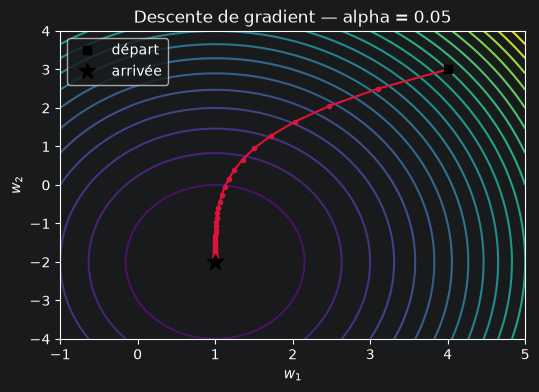

alpha = 0.3 : 60 mises à jour, point final = [ 1.000005 -2.      ], J = 6.34106e-11


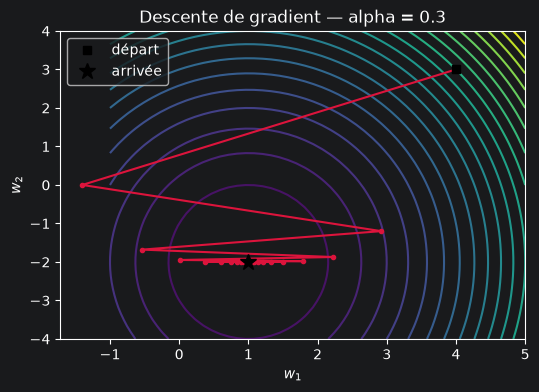

In [4]:
def J_quad(w):
    return 3 * (w[0] - 1) ** 2 + (w[1] + 2) ** 2


def show_history(history, cost_fun, xlim, ylim, title=""):
    a_values, b_values = np.meshgrid(
        np.linspace(*xlim), np.linspace(*ylim)
    )
    Z = np.array(
        [cost_fun([a, b]) for a, b in zip(a_values.flat, b_values.flat)]
    ).reshape(a_values.shape)
    plt.figure()
    plt.contour(a_values, b_values, Z, levels=20, cmap="viridis")
    h = np.array(history)
    plt.plot(h[:, 0], h[:, 1], "o-", color="crimson", markersize=3)
    plt.plot(h[0, 0], h[0, 1], "ks", label="départ")
    plt.plot(h[-1, 0], h[-1, 1], "k*", markersize=12, label="arrivée")
    plt.legend()
    plt.title(title)
    plt.xlabel("$w_1$")
    plt.ylabel("$w_2$")
    plt.show()


for alpha in [0.05, 0.3]:  # Deux expériences indépendantes, une pour chaque pas.
    w_star, hist = gradient_descent(
        J_quad, w_init=[4.0, 3.0], alpha=alpha, epochs=60
    )
    print(f"alpha = {alpha} : {len(hist) - 1} mises à jour, "
          f"point final = {np.round(w_star, 6)}, J = {J_quad(w_star):.6g}")
    show_history(
        hist, J_quad, xlim=(-1, 5), ylim=(-4, 4),
        title=f"Descente de gradient — alpha = {alpha}"
    )

**Vos observations :** pourquoi la trajectoire zigzague-t-elle pour l'un des deux `alpha` et pas pour l'autre ?

Le minimum exact est **(1, −2)**, où les deux termes carrés sont nuls et donc J = 0. Le gradient est `(6*(w1-1), 2*(w2+2))` : la fonction est trois fois plus courbée dans la première direction que dans la seconde.

- **alpha = 0.05** : la trajectoire se rapproche du minimum sans changer de côté sur chaque axe. Les erreurs `w1-1` et `w2+2` sont multipliées respectivement par `1-6*alpha = 0.7` et `1-2*alpha = 0.9` à chaque mise à jour. Elles diminuent sans changer de signe ; la seconde diminue plus lentement. Après 60 mises à jour, le point est proche du minimum mais le critère d'arrêt très strict n'est pas encore atteint.
- **alpha = 0.3** : l'erreur sur la première coordonnée est multipliée par **−0.8**, celle sur la seconde par **0.4**. La première change donc de signe à chaque pas : on dépasse alternativement le minimum à gauche puis à droite. Cela explique le zigzag. Les deux facteurs ont une valeur absolue inférieure à 1, donc les oscillations s'atténuent et la méthode converge.

La **Hessienne** est la matrice qui décrit la courbure de la fonction ; ici elle est diagonale, avec les valeurs 6 et 2. Son **conditionnement** est leur rapport, 6/2 = **3** : les deux directions ne se corrigent pas à la même vitesse. Un pas trop grand ferait diverger la méthode ; ici il faut `0 < alpha < 1/3` pour que les deux erreurs tendent vers zéro.

**Lecture du code ajouté :**

- `gk = np.array(g(w))` : calcule le gradient au point actuel et le convertit en tableau NumPy.
- `if np.linalg.norm(gk) < eps:` : compare la longueur du gradient au seuil de précision.
- `break` : quitte la boucle si cette précision est atteinte.
- `w = w - alpha * gk` : avance dans le sens de la diminution de la fonction ; `alpha` règle la taille du pas.
- `history.append(w.copy())` : ajoute une copie du nouveau point à la liste, pour pouvoir tracer tout le parcours.
- `for alpha in [0.05, 0.3]:` : répète l'expérience avec chacun des deux pas.
- `w_star, hist = gradient_descent(...)` : récupère le point final et l'historique, en repartant de `(4, 3)` pour au plus 60 mises à jour. Le nom `w_star` désigne ici une approximation du minimum.
- `print(...)` : affiche le pas, le nombre de mises à jour, le point obtenu et son coût. `len(hist)-1` retire le point initial du décompte ; `np.round` ne modifie que la présentation du point.
- `show_history(...)` : utilise la fonction de tracé déjà fournie. `hist` est le parcours, `J_quad` la fonction à représenter, `xlim` et `ylim` les limites des axes ; la chaîne `f"...{alpha}"` insère le pas dans le titre.

## Exercice 2 — Méthodes accélérées : momentum & Nesterov

**2.1** Implémentez le **momentum (heavy-ball)** :
$$ \mathbf{v}_{k+1} = \beta \mathbf{v}_k - \alpha \nabla J(\mathbf{w}_k), \qquad \mathbf{w}_{k+1} = \mathbf{w}_k + \mathbf{v}_{k+1} $$
et le **gradient accéléré de Nesterov** :
$$ \mathbf{v}_{k+1} = \beta \mathbf{v}_k - \alpha \nabla J(\mathbf{w}_k + \beta \mathbf{v}_k), \qquad \mathbf{w}_{k+1} = \mathbf{w}_k + \mathbf{v}_{k+1} $$
Les deux se codent dans **une seule** fonction `momentum_gd` : le paramètre `nesterov` choisit si le gradient est évalué en `w` (momentum) ou au point "anticipé" `w + beta*v` (Nesterov).

In [5]:
def momentum_gd(cost_fun, w_init, alpha, beta, epochs, eps=1e-12, nesterov=False):
    w = np.array(w_init, dtype=float)
    v = np.zeros_like(w)  # Vitesse initiale nulle.
    history = [w.copy()]
    g = grad(cost_fun)
    for k in range(epochs):
        lookahead = w + beta * v if nesterov else w
        gk = np.array(g(lookahead))
        # Nesterov : vérifier aussi le gradient du point effectivement renvoyé.
        if np.linalg.norm(gk) < eps and np.linalg.norm(g(w)) < eps:
            break
        v = beta * v - alpha * gk
        w = w + v
        history.append(w.copy())
    return w, history


**✅ Vérification 2.1** — même test que pour l'Exercice 1 (doit converger vers $w=3$, avec et sans Nesterov).

In [6]:
_w1, _h1 = momentum_gd(_J1d, w_init=[0.0], alpha=0.1, beta=0.5, epochs=500, eps=1e-10, nesterov=False)
_w2, _h2 = momentum_gd(_J1d, w_init=[0.0], alpha=0.1, beta=0.5, epochs=500, eps=1e-10, nesterov=True)
assert abs(_w1[0] - 3.0) < 1e-2, f"momentum : attendu w*≈3.0, obtenu {_w1[0]}"
assert abs(_w2[0] - 3.0) < 1e-2, f"nesterov : attendu w*≈3.0, obtenu {_w2[0]}"
print(f"OK : momentum -> w*={_w1[0]:.4f} en {len(_h1)-1} it. ; nesterov -> w*={_w2[0]:.4f} en {len(_h2)-1} it.")


OK : momentum -> w*=3.0000 en 67 it. ; nesterov -> w*=3.0000 en 54 it.


**2.2** Comparez, sur le même quadratique mal conditionné $J\_quad$ ($\alpha = 0.15$), le nombre d'itérations nécessaires pour atteindre $\|\nabla J\| < 10^{-6}$ pour : descente de gradient simple, momentum ($\beta=0.8$), Nesterov ($\beta=0.8$). Complétez la boucle `for name, fn in [...]` (donnez à chaque `fn` un appel à `gradient_descent` ou `momentum_gd` avec les bons paramètres) ; le tracé du diagramme en barres est déjà écrit.

Descente de gradient  :   46 itérations -> w* = [ 1. -2.], norme du gradient = 7.49e-07
Momentum              :  146 itérations -> w* = [ 1. -2.], norme du gradient = 9.80e-07
Nesterov              :   56 itérations -> w* = [ 1. -2.], norme du gradient = 8.53e-07


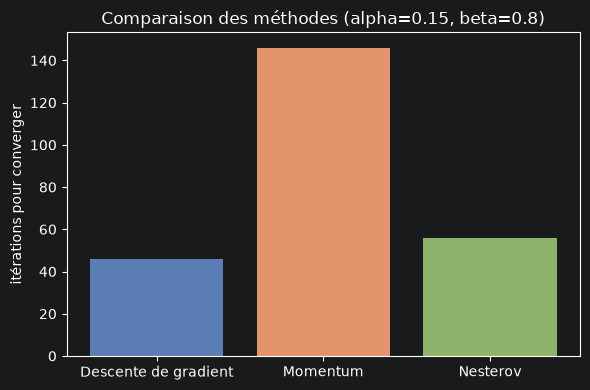

In [7]:
results = {}
histories_ex2 = {}
for name, fn in [
    ("Descente de gradient", lambda: gradient_descent(J_quad, [4.0, 3.0], 0.15, 500, eps=1e-6)),
    ("Momentum", lambda: momentum_gd(J_quad, [4.0, 3.0], 0.15, 0.8, 500, eps=1e-6)),
    ("Nesterov", lambda: momentum_gd(J_quad, [4.0, 3.0], 0.15, 0.8, 500, eps=1e-6, nesterov=True)),
]:
    w_star, hist = fn()
    results[name] = len(hist) - 1
    histories_ex2[name] = hist
    grad_norm = np.linalg.norm(grad(J_quad)(w_star))
    assert grad_norm < 1e-6, f"{name} : seuil de convergence non atteint"
    print(f"{name:22s}: {len(hist)-1:4d} itérations -> w* = {np.round(w_star, 4)}, norme du gradient = {grad_norm:.2e}")

plt.figure()
plt.bar(results.keys(), results.values(), color=["#5B7FB5", "#E3946A", "#8CB369"])
plt.ylabel("itérations pour converger")
plt.title("Comparaison des méthodes (alpha=0.15, beta=0.8)")
plt.tight_layout()
plt.show()


**Observations.** Avec le même point initial, alpha = 0.15, beta = 0.8 et le seuil 10^-6, la descente simple prend **46 mises à jour**, momentum **146**, et Nesterov **56**. La Hessienne est diag(6, 2), donc son conditionnement est seulement **3**. La descente simple est déjà efficace avec ce pas ; l'inertie de momentum prolonge ici les oscillations. Les méthodes dites accélérées ne gagnent donc pas systématiquement avec n'importe quels paramètres.

Le gradient de Nesterov est calculé au point anticipé ; le critère d'arrêt vérifie aussi le gradient du point effectivement renvoyé pour comparer la même précision entre les trois méthodes.

Pour explorer un problème plus mal conditionné, le calcul ci-dessous remplace le coefficient 3 par 30 (conditionnement 30). Le pas est ramené à 0.015 pour les trois méthodes : conserver 0.15 dépasserait le seuil 1/30 de stabilité de la descente simple. Les autres paramètres et le point initial restent identiques.

In [8]:
def J_quad_30(w):
    return 30*(w[0]-1)**2 + (w[1]+2)**2

results_30 = {}
for name, fn in [
    ("Descente de gradient", lambda: gradient_descent(J_quad_30, [4.0, 3.0], 0.015, 3000, eps=1e-6)),
    ("Momentum", lambda: momentum_gd(J_quad_30, [4.0, 3.0], 0.015, 0.8, 3000, eps=1e-6)),
    ("Nesterov", lambda: momentum_gd(J_quad_30, [4.0, 3.0], 0.015, 0.8, 3000, eps=1e-6, nesterov=True)),
]:
    point, path = fn()
    assert np.linalg.norm(grad(J_quad_30)(point)) < 1e-6
    results_30[name] = len(path)-1
    print(f"{name:22s} : {len(path)-1} mises à jour")
print("Le gain éventuel dépend du conditionnement et du choix conjoint du pas et de l'inertie.")


Descente de gradient   : 530 mises à jour
Momentum               : 164 mises à jour
Nesterov               : 110 mises à jour
Le gain éventuel dépend du conditionnement et du choix conjoint du pas et de l'inertie.


Avec le coefficient 30 et le pas 0.015, on obtient **530 mises à jour** pour la descente simple, **164** pour momentum et **110** pour Nesterov. Ici, l'accélération est utile. Cette expérience utilise un autre pas adapté à la courbure : elle ne démontre pas qu'un algorithme domine toujours les autres.

## Exercice 3 — Optimisation continue sous contraintes

Considérons
$$ \min_{x_1,x_2} \; (x_1 - 3/2)^2 + (x_2 - 1/2)^4 \quad \text{s.c.} \quad |x_1| + |x_2| \le 1 .$$

**3.1** Résolvez-le de **trois façons indépendantes**, une cellule à la fois, et vérifiez qu'elles s'accordent.

**(a) Barrière logarithmique.** L'idée : remplacer les 4 contraintes linéaires équivalentes à $|x_1|+|x_2|\le 1$ (à savoir $g_i(x)\ge 0$ pour $g_1=1-x_1-x_2$, $g_2=1+x_1+x_2$, $g_3=1-x_1+x_2$, $g_4=1+x_1-x_2$) par une pénalité $-\xi\sum_i \log g_i(x)$ ajoutée à l'objectif, et résoudre un problème **non contraint** avec `scipy.optimize.minimize` (méthode Nelder-Mead).

In [9]:
import cvxpy as cp
from scipy.optimize import minimize

def f0(x1, x2):
    return (x1 - 1.5) ** 2 + (x2 - 0.5) ** 4

def f0_barrier(x, xi=0.05):
    x1, x2 = x
    g = np.array([1-x1-x2, 1+x1+x2, 1-x1+x2, 1+x1-x2])
    if np.min(g) <= 0:
        return np.inf  # Le logarithme est réservé à l'intérieur strict du losange.
    return f0(x1, x2) - xi * np.sum(np.log(g))

sol_barrier = minimize(f0_barrier, x0=[0.0, 0.0], args=(0.01,),
                       method="Nelder-Mead",
                       options={"xatol": 1e-10, "fatol": 1e-12, "maxiter": 5000})
assert sol_barrier.success, sol_barrier.message
assert np.abs(sol_barrier.x).sum() < 1
print("solution barrière :", sol_barrier.x, "f0 =", f0(*sol_barrier.x))


solution barrière : [0.97644223 0.01045561] f0 = 0.33154663663655104


**(b) SLSQP avec contraintes explicites.** Cette fois, on passe directement les 4 contraintes $g_i(x)\ge 0$ à `scipy.optimize.minimize(..., method="SLSQP", constraints=...)`, sans les transformer en pénalité.

In [10]:
cons = (
    {"type": "ineq", "fun": lambda x: 1-x[0]-x[1]},
    {"type": "ineq", "fun": lambda x: 1+x[0]+x[1]},
    {"type": "ineq", "fun": lambda x: 1-x[0]+x[1]},
    {"type": "ineq", "fun": lambda x: 1+x[0]-x[1]},
)
sol_slsqp = minimize(lambda x: f0(x[0], x[1]), x0=[0.0, 0.0],
                     method="SLSQP", constraints=cons,
                     options={"ftol": 1e-12, "maxiter": 1000})
assert sol_slsqp.success, sol_slsqp.message
assert np.abs(sol_slsqp.x).sum() <= 1 + 1e-8
print("solution SLSQP    :", sol_slsqp.x, "f0 =", f0(*sol_slsqp.x))


solution SLSQP    : [ 1.00000000e+00 -3.88578059e-16] f0 = 0.31250000000000155


**(c) `cvxpy`.** Le problème est convexe : formulez-le directement en `cvxpy` (variables, contrainte `cp.abs(x1) + cp.abs(x2) <= 1`, objectif, `prob.solve()`).

In [11]:
x1, x2 = cp.Variable(), cp.Variable()
constraints = [cp.abs(x1) + cp.abs(x2) <= 1]
obj = cp.Minimize(cp.square(x1 - 1.5) + cp.power(x2 - 0.5, 4))
prob = cp.Problem(obj, constraints)
prob.solve()
assert prob.status == cp.OPTIMAL, prob.status
assert abs(x1.value) + abs(x2.value) <= 1 + 1e-6
print("solution cvxpy    :", x1.value, x2.value, "f0 =", prob.value)


solution cvxpy    : 0.9999999934456898 2.218611322625575e-09 f0 = 0.3125000054450046


**✅ Vérification 3.1** — les trois méthodes doivent tomber sur (à peu près) le même point.

In [12]:
_pts = {
    "barrière": np.array(sol_barrier.x),
    "SLSQP": np.array(sol_slsqp.x),
    "cvxpy": np.array([x1.value, x2.value]),
}
for name, p in _pts.items():
    print(f"  {name:10s}: {np.round(p, 4)}")
_ref = _pts["SLSQP"]
for name, p in _pts.items():
    assert np.linalg.norm(p - _ref) < 0.05, f"{name} s'écarte trop de SLSQP : {p} vs {_ref}"
print("OK : les trois méthodes s'accordent (à 0.05 près).")


  barrière  : [0.9764 0.0105]
  SLSQP     : [ 1. -0.]
  cvxpy     : [1. 0.]
OK : les trois méthodes s'accordent (à 0.05 près).


**3.2 — Multiplicateurs de Lagrange à la main.** Écrivez les quatre contraintes sous la forme $g_i(x) \ge 0$ :
$$ g_1 = 1-x_1-x_2,\quad g_2 = 1+x_1+x_2,\quad g_3 = 1-x_1+x_2,\quad g_4 = 1+x_1-x_2 . $$
Identifiez numériquement quelles $g_i$ sont actives (nulles) à l'optimum — vous devriez trouver **deux** contraintes actives simultanément, car l'optimum se situe exactement sur un *sommet* du losange $|x_1|+|x_2|\le 1$ (le même phénomène qu'un sommet optimal du polytope d'un PL !). Sur une feuille, écrivez la condition de stationnarité KKT avec les deux multiplicateurs correspondants,
$$ \nabla f_0(x^\star) = \mu_1 \nabla g_1(x^\star) + \mu_3 \nabla g_3(x^\star), \qquad \mu_1,\mu_3 \ge 0, $$
résolvez le système linéaire 2×2 obtenu **à la main**, puis codez le même calcul ci-dessous pour vérifier votre résultat papier.

In [13]:
x_star = np.array(sol_slsqp.x)
g = np.array([1-x_star[0]-x_star[1], 1+x_star[0]+x_star[1],
              1-x_star[0]+x_star[1], 1+x_star[0]-x_star[1]])
print("valeurs des contraintes g1..g4 :", np.round(g, 8), " (0 = active)")

grad_f0 = np.array([2*(x_star[0]-1.5), 4*(x_star[1]-0.5)**3])
M = np.array([[-1.0, -1.0], [-1.0, 1.0]])  # Gradients g1 et g3 en colonnes.
mu = np.linalg.solve(M, grad_f0)
mu_complet = np.array([mu[0], 0.0, mu[1], 0.0])
assert np.all(g >= -1e-8)
assert np.max(np.abs(mu_complet * g)) < 1e-8
print("mu1, mu3 =", np.round(mu, 8))
print("Complémentarité : mu_i * g_i =", np.round(mu_complet * g, 10))


valeurs des contraintes g1..g4 : [0. 2. 0. 2.]  (0 = active)
mu1, mu3 = [0.75 0.25]
Complémentarité : mu_i * g_i = [0. 0. 0. 0.]


**✅ Vérification 3.2** — la stationnarité KKT doit être satisfaite (résidu quasi nul) et les deux multiplicateurs doivent être positifs.

In [14]:
_grad_g1, _grad_g3 = np.array([-1, -1]), np.array([-1, 1])
_residual = grad_f0 - (mu[0] * _grad_g1 + mu[1] * _grad_g3)
assert np.linalg.norm(_residual) < 1e-4, f"stationnarité KKT non vérifiée, résidu = {_residual}"
assert mu[0] > -1e-6 and mu[1] > -1e-6, f"les deux multiplicateurs doivent être >= 0, obtenu {mu}"
print(f"OK : résidu KKT = {np.linalg.norm(_residual):.2e}, mu = {np.round(mu, 4)} (>= 0)")


OK : résidu KKT = 0.00e+00, mu = [0.75 0.25] (>= 0)


**Calcul à la main des multiplicateurs et interprétation.** À x* = (1, 0), g1 = g3 = 0 et g2 = g4 = 2. Le gradient du coût vaut (-1, -1/2). Les gradients des deux contraintes actives sont (-1, -1) et (-1, 1). La stationnarité donne :

- -mu1 - mu3 = -1, donc mu1 + mu3 = 1 ;
- -mu1 + mu3 = -1/2, donc mu1 - mu3 = 1/2.

En additionnant : 2 mu1 = 3/2, d'où **mu1 = 3/4** et **mu3 = 1/4**. Les deux autres multiplicateurs sont nuls. L'admissibilité, la positivité des multiplicateurs, la stationnarité et la complémentarité sont satisfaites. Le problème étant convexe, ces conditions certifient le minimum global **f0(1, 0) = 5/16 = 0.3125**.

La barrière avec xi = 0.01 donne environ (0.976442, 0.010456), de coût 0.331547. Elle reste strictement à l'intérieur et approche le problème original sans atteindre exactement sa frontière pour un paramètre non nul. SLSQP et CVXPY retrouvent le sommet (1, 0). L'écart de la barrière est conforme à la tolérance 0.05 demandée.

## Exercice 4 — Programmation linéaire : mix de production

Avant l'extension de sa gamme avec le modèle **Sport** (voir le Projet, Partie 1 ci-dessous, pour la gamme réelle à trois produits), ExedBike ne fabriquait que deux modèles de vélos électriques : **Urban** (marge 120€/unité) et **Cargo** (marge 200€/unité) — c'est cette version simplifiée, déjà résolue à la main en TD1 (Partie ExedBike — Résolution), que nous reprenons ici pour la vérifier avec un solveur.
Chaque semaine, l'usine dispose de **480 heures de main-d'œuvre**, **900 kg d'aluminium pour batteries**, et **240 heures-machine**.

| Ressource            | Urban | Cargo | Disponible |
|---------------------|:----:|:----:|:---:|
| Main-d'œuvre (h/unité)      | 4    | 6    | 480 |
| Aluminium (kg/unité)  | 6    | 15    | 900 |
| Temps machine (h/unité)| 2    | 2    | 240 |

**4.1a** Formulez et résolvez le PL avec `scipy.optimize.linprog` (rappel : `linprog` **minimise** — pour maximiser la marge, minimisez son opposé).

In [15]:
from scipy.optimize import linprog

# linprog minimise : les marges sont donc changées de signe.
c = np.array([-120.0, -200.0])
A_ub = np.array([[4.0, 6.0], [6.0, 15.0], [2.0, 2.0]])
b_ub = np.array([480.0, 900.0, 240.0])

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=(0, None), method="highs")
assert res.success, res.message
print("scipy.optimize.linprog :")
print("  Urban =", round(res.x[0], 2), " Cargo =", round(res.x[1], 2),
      " marge hebdomadaire =", round(-res.fun, 2), "€")


scipy.optimize.linprog :
  Urban = 75.0  Cargo = 30.0  marge hebdomadaire = 15000.0 €


**4.1b** Formulez le **même** PL avec `PuLP` (langage plus proche de l'écriture mathématique : variables, objectif à *maximiser* directement, contraintes une par une).

In [16]:
import pulp

prob = pulp.LpProblem("ExedBike_mix", pulp.LpMaximize)
u = pulp.LpVariable("Urban", lowBound=0, cat="Continuous")
cg = pulp.LpVariable("Cargo", lowBound=0, cat="Continuous")
prob += 120*u + 200*cg, "Marge"
prob += 4*u + 6*cg <= 480, "Main_oeuvre"
prob += 6*u + 15*cg <= 900, "Aluminium"
prob += 2*u + 2*cg <= 240, "Temps_machine"

prob.solve(pulp.PULP_CBC_CMD(msg=False))
assert prob.status == pulp.LpStatusOptimal, pulp.LpStatus[prob.status]
print("Statut PuLP :", pulp.LpStatus[prob.status])
print("Urban =", u.value(), " Cargo =", cg.value(), " marge =", pulp.value(prob.objective), "€")
for name, con in prob.constraints.items():
    print(f"  {name:14s} marge de manoeuvre = {con.slack:.2f} (saturée : {abs(con.slack) < 1e-6})")


Statut PuLP : Optimal
Urban = 75.0  Cargo = 30.0  marge = 15000.0 €
  Main_oeuvre    marge de manoeuvre = -0.00 (saturée : True)
  Aluminium      marge de manoeuvre = -0.00 (saturée : True)
  Temps_machine  marge de manoeuvre = 30.00 (saturée : False)


**✅ Vérification 4.1** — `scipy` et `PuLP` doivent donner exactement la même marge optimale (et la même que votre tableau de simplexe à la main en TD1 : 15 000 €).

In [17]:
_obj_scipy = -res.fun
_obj_pulp = pulp.value(prob.objective)
assert abs(_obj_scipy - _obj_pulp) < 1e-2, f"scipy ({_obj_scipy}) et PuLP ({_obj_pulp}) ne s'accordent pas"
assert abs(_obj_scipy - 15000) < 1.0, f"attendu 15 000 € (cf. TD1), obtenu {_obj_scipy}"
print(f"OK : scipy = {_obj_scipy:.2f} € ; PuLP = {_obj_pulp:.2f} € ; TD1 (à la main) = 15000 €")


OK : scipy = 15000.00 € ; PuLP = 15000.00 € ; TD1 (à la main) = 15000 €


**4.2** Quelles contraintes sont saturées à l'optimum ? Correspondent-elles au sommet identifié à la main en TD ? Sur quelle ressource faudrait-il investir en priorité ? Affichez les prix duaux (`prob.constraints[name].pi` en PuLP, `res.ineqlin.marginals` en `linprog`) et interprétez-les.

In [18]:
resource_names = ["Main_oeuvre", "Aluminium", "Temps_machine"]
units = ["€/h", "€/kg", "€/h-machine"]
print("Prix duaux PuLP (objectif de maximisation) :")
for name, unit in zip(resource_names, units):
    print(f"  {name:14s} : {prob.constraints[name].pi:.6f} {unit}")
print()
print("Valeurs duales brutes SciPy (objectif de minimisation) :", res.ineqlin.marginals)
dual_mix2 = -res.ineqlin.marginals  # Retour au gain de marge pour un relâchement.
print("Prix duaux SciPy convertis en gains de marge :", dual_mix2)
assert np.allclose(dual_mix2, [prob.constraints[n].pi for n in resource_names], atol=1e-6)
assert np.allclose(A_ub @ res.x + res.ineqlin.residual, b_ub)
assert np.allclose(dual_mix2 * res.ineqlin.residual, 0, atol=1e-7)
print("Consommations :", A_ub @ res.x)
print("Ressources restantes :", res.ineqlin.residual)


Prix duaux PuLP (objectif de maximisation) :
  Main_oeuvre    : 25.000000 €/h
  Aluminium      : 3.333333 €/kg
  Temps_machine  : -0.000000 €/h-machine

Valeurs duales brutes SciPy (objectif de minimisation) : [-25.          -3.33333333  -0.        ]
Prix duaux SciPy convertis en gains de marge : [25.          3.33333333  0.        ]
Consommations : [480. 900. 210.]
Ressources restantes : [ 0.  0. 30.]


**Interprétation économique (deux produits).** Le plan optimal est **75 Urban et 30 Cargo**, pour **15 000 €/semaine**. La main-d'œuvre (480/480 h) et l'aluminium (900/900 kg) sont saturés ; le temps machine utilise 210/240 h, soit 30 h restantes. Ce sont bien les deux droites actives au sommet calculé par le simplexe dans le TD.

Au voisinage de cet optimum, une heure de main-d'œuvre supplémentaire vaut **25 €** de marge, un kilogramme d'aluminium **10/3 ≈ 3.33 €**, une heure-machine **0 €**. La main-d'œuvre est la piste prioritaire à examiner, mais une décision d'investissement exige de comparer ces gains aux coûts d'achat dans leurs unités respectives. Ces valeurs sont locales, tant que la structure de la solution optimale reste valable.

SciPy minimise l'opposé de la marge : ses valeurs duales brutes ont donc le signe opposé aux prix duaux économiques affichés par PuLP. **Comparaison Excel confirmée.** La feuille « 2 - Mix production » et le « Rapport de la sensibilité 1 » du 12/10/2026 à 20:39:03 donnent 75 Urban, 30 Cargo, 15 000 € et les mêmes prix duaux (25 ; 3,333333 ; 0), à l’arrondi près.

---
## Projet individuel ExedBike — Partie 1 (à rendre avant la Séance 2)

Vous allez travailler sur ce **projet fil rouge** tout au long des trois séances. Lisez le brief complet du projet (document séparé) pour le contexte, les jalons et les critères d'évaluation. Voici la **Partie 1** — contrairement aux exercices précédents, **c'est votre travail individuel noté** : il n'y a pas de cellule de vérification qui vous donne la réponse.

### 1. Ajuster un modèle de coût de production (optimisation continue)

Les données ci-dessous forment un jeu de données synthétique du coût unitaire de production en fonction du volume cumulé produit pour le modèle Urban (un effet classique de **courbe d'apprentissage** : le coût baisse avec l'expérience accumulée). Le modèle est une loi de puissance,
$$ c(q) = k\, q^{-\theta}, \qquad \theta \in (0,1). $$
En passant au logarithme, ceci devient une **régression linéaire** : $\log c(q) = \log k - \theta \log q$.

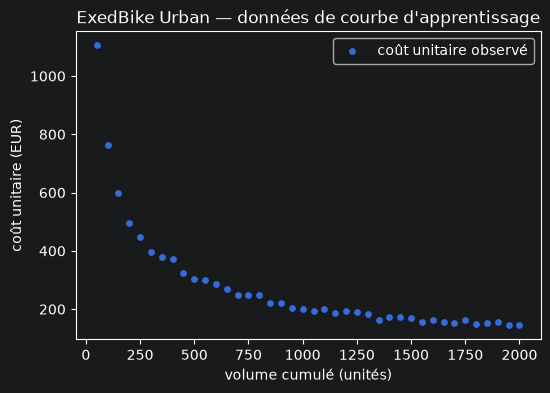

In [19]:
# Jeu de données synthétique (ne changez pas la graine : les résultats doivent être reproductibles)
rng = np.random.default_rng(7)
q = np.linspace(50, 2000, 40)
k_true, theta_true = 9500.0, 0.55
c_obs = k_true * q ** (-theta_true) * np.exp(rng.normal(0, 0.04, size=q.shape))

plt.figure()
plt.scatter(q, c_obs, s=15, label="coût unitaire observé")
plt.xlabel("volume cumulé (unités)")
plt.ylabel("coût unitaire (EUR)")
plt.title("ExedBike Urban — données de courbe d'apprentissage")
plt.legend()
plt.show()


Ajustez $(\log k, \theta)$ en minimisant l'erreur quadratique moyenne **avec votre propre implémentation de la descente de gradient** (celle de l'Exercice 1, réutilisable telle quelle) sur les données log-log **standardisées**, puis reportez $(k,\theta)$ dans les unités d'origine. Tracez les données et l'ajustement, ainsi que la courbe de convergence, et expliquez (dans votre synthèse d'une page) pourquoi standardiser $\log q$ compte ici (faites le lien avec le mauvais conditionnement observé à l'Exercice 1.2).

Étapes suggérées :
1. `x = log(q)`, `y = log(c_obs)` ;
2. standardisez `x` : `x_z = (x - x.mean()) / x.std()` ;
3. définissez `J_fit(params)` = EQM entre `p0 - p1*x_z` et `y` (avec `params=[p0,p1]`, en utilisant `anp` pour que `autograd` puisse dériver) ;
4. `gradient_descent(J_fit, w_init=[0.0, 0.0], alpha=..., epochs=...)` ;
5. dé-standardisez : `theta_hat = p1/x_std`, `k_hat = exp(p0 + p1*x_mean/x_std)` ;
6. tracez le nuage de points + la courbe $k\_hat \cdot q^{-\theta\_hat}$, et la courbe de convergence de la perte.

Convergence en 114 mises à jour ; norme du gradient = 9.847e-11
k = 9682.847422 ; theta = 0.555228 ; EQM log-log = 0.00103054
Conditionnement de la Hessienne : avant = 2871.98, après = 1.00


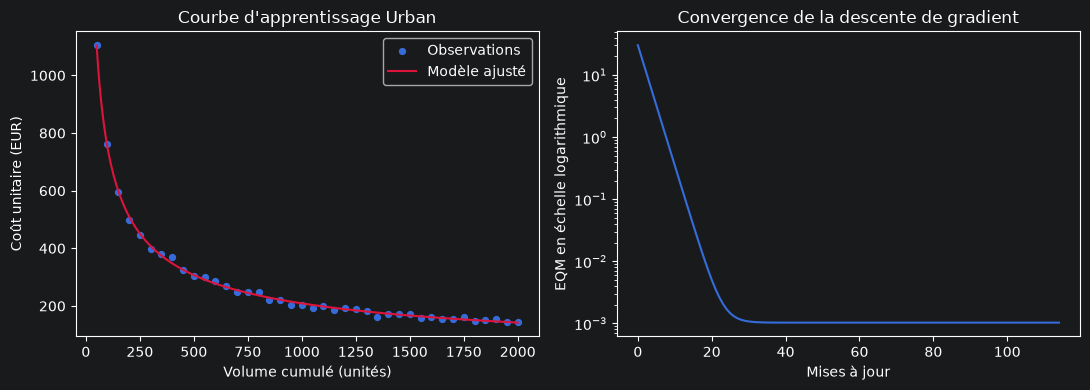

In [20]:
# Ajustement des données fournies, sans changer la graine ni les observations.
x = np.log(q)
y = np.log(c_obs)
x_mean, x_std = x.mean(), x.std()
x_z = (x - x_mean) / x_std

def J_fit(params):
    predictions = params[0] - params[1] * x_z
    return anp.mean((predictions - y) ** 2)

fit_params, hist_fit = gradient_descent(
    J_fit, w_init=[0.0, 0.0], alpha=0.1, epochs=2000, eps=1e-10
)
p0, p1 = fit_params
theta_hat = p1 / x_std
k_hat = np.exp(p0 + p1 * x_mean / x_std)
fit_losses = np.array([J_fit(p) for p in hist_fit])
fit_grad_norm = np.linalg.norm(grad(J_fit)(fit_params))
assert fit_grad_norm < 1e-10, "La descente de gradient n'a pas convergé."
assert k_hat > 0 and 0 < theta_hat < 1
assert np.all(np.diff(fit_losses) <= 1e-12)

# Vérification indépendante seulement : la solution présentée vient bien de notre descente.
fit_reference = np.linalg.lstsq(np.column_stack([np.ones_like(x_z), -x_z]), y, rcond=None)[0]
assert np.allclose(fit_params, fit_reference, atol=1e-8, rtol=0)
X_raw = np.column_stack([np.ones_like(x), -x])
X_scaled = np.column_stack([np.ones_like(x_z), -x_z])
cond_raw = np.linalg.cond(2 * X_raw.T @ X_raw / len(x))
cond_scaled = np.linalg.cond(2 * X_scaled.T @ X_scaled / len(x))

print(f"Convergence en {len(hist_fit)-1} mises à jour ; norme du gradient = {fit_grad_norm:.3e}")
print(f"k = {k_hat:.6f} ; theta = {theta_hat:.6f} ; EQM log-log = {J_fit(fit_params):.8f}")
print(f"Conditionnement de la Hessienne : avant = {cond_raw:.2f}, après = {cond_scaled:.2f}")

q_plot = np.linspace(q.min(), q.max(), 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(q, c_obs, s=18, label="Observations")
axes[0].plot(q_plot, k_hat*q_plot**(-theta_hat), color="crimson", label="Modèle ajusté")
axes[0].set(xlabel="Volume cumulé (unités)", ylabel="Coût unitaire (EUR)", title="Courbe d'apprentissage Urban")
axes[0].legend()
axes[1].semilogy(fit_losses)
axes[1].set(xlabel="Mises à jour", ylabel="EQM en échelle logarithmique", title="Convergence de la descente de gradient")
fig.tight_layout()
plt.show()


**Résultats du modèle de coût.** La descente de gradient donne **k ≈ 9682.85** et **theta ≈ 0.555228**, après **114 mises à jour** (alpha = 0.1, seuil 10^-10). L'erreur quadratique moyenne sur les logarithmes est **0.00103054**. Le coût estimé est donc c(q) ≈ 9682.85 × q^(-0.555228), sur la plage observée de 50 à 2000 unités cumulées.

Un theta positif traduit un coût décroissant avec l'expérience accumulée. Le paramètre k est l'échelle du modèle (valeur théorique à q = 1, en dehors de la plage observée, à ne pas présenter comme une mesure). L'ajustement porte sur les logarithmes : les erreurs évaluées sont des écarts de log-coût.

Centrer et réduire log(q) fait passer le conditionnement de la Hessienne de **2871.98 à 1** : les deux paramètres ont alors des courbures équilibrées, ce qui permet un pas stable et une convergence rapide. Après le calcul, on revient aux unités originales par theta = p1 / écart-type(log q) et k = exp(p0 + p1 × moyenne(log q) / écart-type(log q)). Les moindres carrés sont utilisés uniquement comme contrôle indépendant de la descente programmée.

### 2. PL du mix de production pour la gamme réelle

ExedBike vend en réalité **trois** modèles : Urban, Cargo et Sport, avec les données ci-dessous. Formulez et résolvez le PL du mix de production hebdomadaire (maximiser la marge sous les contraintes de ressources) avec `PuLP` **ou** `scipy.optimize.linprog` — vous savez déjà faire les deux depuis l'Exercice 4, c'est la même démarche avec un troisième produit. Reportez le mix optimal, la marge, les contraintes saturées et les prix duaux, et donnez une phrase d'interprétation métier pour chaque prix dual.

| Ressource | Urban | Cargo | Sport | Disponible |
|---|:--:|:--:|:--:|:--:|
| Main-d'œuvre (h/unité) | 4 | 6 | 5 | 520 |
| Aluminium (kg/unité) | 6 | 15 | 9 | 1100 |
| Temps machine (h/unité) | 2 | 2 | 3 | 260 |
| Marge (€/unité) | 120 | 200 | 175 | — |

In [21]:
# Variables continues : quantités hebdomadaires Urban, Cargo et Sport.
products = ["Urban", "Cargo", "Sport"]
margins3 = np.array([120.0, 200.0, 175.0])
A3 = np.array([[4.0, 6.0, 5.0], [6.0, 15.0, 9.0], [2.0, 2.0, 3.0]])
b3 = np.array([520.0, 1100.0, 260.0])
res3 = linprog(-margins3, A_ub=A3, b_ub=b3, bounds=(0, None), method="highs")
assert res3.success, res3.message
usage3 = A3 @ res3.x
slack3 = b3 - usage3
dual3 = -res3.ineqlin.marginals

for name, quantity in zip(products, res3.x):
    print(f"{name} : {quantity:.6f} unités/semaine")
print(f"Marge optimale : {-res3.fun:.2f} €/semaine")
for name, used, cap, slack, price, unit in zip(resource_names, usage3, b3, slack3, dual3, units):
    print(f"{name:14s} : {used:.2f}/{cap:.2f}, reste = {slack:.2f}, "
          f"saturée = {abs(slack)<1e-7}, prix dual = {price:.2f} {unit}")

# Certificat d'optimalité : admissibilité, dualité forte et complémentarité.
assert np.all(res3.x >= -1e-8) and np.all(slack3 >= -1e-8)
assert np.all(dual3 >= -1e-8) and np.all(A3.T @ dual3 >= margins3 - 1e-8)
assert abs(b3 @ dual3 - margins3 @ res3.x) < 1e-7
assert np.allclose(dual3 * slack3, 0, atol=1e-7)
assert np.allclose((A3.T @ dual3 - margins3) * res3.x, 0, atol=1e-7)
# Confirmer chaque prix dual par un petit accroissement de la ressource concernée.
for j in range(3):
    b_perturbed = b3.copy()
    b_perturbed[j] += 0.1
    perturbed = linprog(-margins3, A_ub=A3, b_ub=b_perturbed, bounds=(0, None), method="highs")
    assert perturbed.success
    assert abs((-perturbed.fun + res3.fun)/0.1 - dual3[j]) < 1e-6
print("Vérifications primal/dual et variations marginales : OK.")


Urban : 0.000000 unités/semaine
Cargo : 32.500000 unités/semaine
Sport : 65.000000 unités/semaine
Marge optimale : 17875.00 €/semaine
Main_oeuvre    : 520.00/520.00, reste = 0.00, saturée = True, prix dual = 31.25 €/h
Aluminium      : 1072.50/1100.00, reste = 27.50, saturée = False, prix dual = 0.00 €/kg
Temps_machine  : 260.00/260.00, reste = -0.00, saturée = True, prix dual = 6.25 €/h-machine
Vérifications primal/dual et variations marginales : OK.


**Formulation et interprétation du projet.** Pour u, c, s ≥ 0 continus, maximiser **120u + 200c + 175s** sous :

- 4u + 6c + 5s ≤ 520 (heures de main-d'œuvre) ;
- 6u + 15c + 9s ≤ 1100 (kg d'aluminium) ;
- 2u + 2c + 3s ≤ 260 (heures-machine).

Le résultat est **Urban = 0, Cargo = 32.5, Sport = 65**, avec **17 875 €/semaine** de marge. Le PL demandé est continu : 32.5 est une valeur valide dans ce modèle ; imposer des vélos entiers serait un autre problème.

La main-d'œuvre et le temps machine sont entièrement utilisés. L'aluminium laisse **27.5 kg** inutilisés. Au voisinage de la solution, une heure de travail supplémentaire augmente la marge optimale de **31.25 €**, une heure-machine de **6.25 €**, et un kg d'aluminium de **0 €**. Acheter davantage d'aluminium seul n'améliore donc pas la marge actuelle ; les autres achats s'évaluent en comparant leur coût à ces gains marginaux.

Le certificat primal/dual et de petites perturbations des capacités confirment ces prix. Le modèle de coût et le PL sont deux tâches distinctes : les marges du PL restent celles fournies dans l'énoncé. **Comparaison Excel effectuée : écart de paramétrage identifié.** Le « Rapport de la sensibilité 2 » du 12/10/2026 à 20:42:42 utilise les coefficients 2, 2, 3 (temps machine), au lieu de 120, 200, 175 (marge). Il donne 0 Urban, 0 Cargo et 86,666667 Sport ; ce plan admissible rapporte seulement 15 166,67 €. Il faut relancer le Solveur avec l’objectif D17 / Max, les variables C13:C15 et Simplexe PL pour valider la marge dans Excel. Aucune concordance Excel du cas à trois produits n’est affirmée ; ce contrôle croisé est facultatif dans la partie projet. La synthèse d’une page, fondée sur les résultats Python vérifiés, est dans [COMPTE_RENDU_TP1.pdf](COMPTE_RENDU_TP1.pdf).

### Livrables pour la Partie 1

- Ce notebook complété et exécuté : exercices 1 à 5 et les deux tâches du projet.
- La synthèse d’une page : [COMPTE_RENDU_TP1.pdf](COMPTE_RENDU_TP1.pdf), avec les paramètres du coût, le mix optimal et l’interprétation des prix duaux.
- La partie ExedBike du TD dans un fichier dédié : [seance1_simplexe.md](seance1_simplexe.md), avec les quatre réponses et tous les tableaux du simplexe. Le Markdown est autorisé par la consigne.
- Le modèle MiniZinc complété : `Seance1_TP1_minizinc_a_completer.mzn`.

Ce travail sera prolongé en Séances 2 et 3 (décisions sur les lignes de production, ordonnancement, réseau de distribution).

## Exercice 5 — MiniZinc et comparaison des solveurs

Le fichier `Seance1_TP1_minizinc_a_completer.mzn` est complété avec deux variables continues positives, trois contraintes de ressources et la maximisation de 120u + 200c.

**Test réalisé avec HiGHS** : Urban = 75, Cargo = 30, marge = 15 000 €, optimalité certifiée (marqueur `==========`). Même résultat que SciPy, PuLP et le calcul manuel.

**Test réalisé avec Gecode** : arrêt imposé après 20 secondes pour éviter une attente sans borne. Une solution presque nulle a été affichée, sans certificat d'optimalité. Le fait que Gecode termine avec un code de retour 0 ne signifie pas qu'il a résolu le problème à l'optimum. Il recherche ici sur des intervalles de flottants ; HiGHS exploite la structure linéaire.

Commandes exécutées depuis le dossier du projet (bibliothèque HiGHS fournie avec MiniZinc IDE sur ce Mac) :

```sh
minizinc --solver HiGHS --highs-dll /Applications/MiniZincIDE.app/Contents/Resources/lib/libhighs.dylib --statistics TP1/Seance1_TP1_minizinc_a_completer.mzn
minizinc --solver Gecode --time-limit 20000 --statistics TP1/Seance1_TP1_minizinc_a_completer.mzn
```

Le rapport Excel Urban/Cargo confirme aussi ce même optimum, comme détaillé dans l’interprétation de l’exercice 4.

### Exploration facultative — petites et grandes instances
La cellule suivante prépare la petite instance manquante avec le générateur fourni et contrôle indépendamment les deux tailles avec SciPy. Les quantités sont bornées entre 0 et 100000 comme dans le modèle MiniZinc.

In [22]:
from pathlib import Path
from tempfile import TemporaryDirectory
project_root = Path.cwd()
if not (project_root / "generate_instance.py").is_file():
    project_root = project_root.parent
if not (project_root / "generate_instance.py").is_file():
    raise FileNotFoundError("Lancer le notebook depuis TP1 ou depuis la racine du dépôt.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from generate_instance import generate, write_dzn

scale_results = {}
for label, n, m, k_nnz in [("small", 15, 4, 3), ("large", 2000, 80, 6)]:
    margins_scale, usage_scale, capacity_scale = generate(n, m, k_nnz, seed=20260924)
    if label == "small":
        write_dzn(project_root / "small.dzn", margins_scale, usage_scale, capacity_scale)
    else:
        # Vérifier que le générateur reproduit exactement le fichier fourni.
        with TemporaryDirectory() as temp_dir:
            generated_path = Path(temp_dir) / "large.dzn"
            write_dzn(generated_path, margins_scale, usage_scale, capacity_scale)
            assert generated_path.read_bytes() == (project_root / "large.dzn").read_bytes()
    scale_sol = linprog(-margins_scale, A_ub=usage_scale.T,
                        b_ub=capacity_scale, bounds=(0, 100000), method="highs")
    assert scale_sol.success, scale_sol.message
    scale_results[label] = {"marge": float(-scale_sol.fun),
                            "variantes": int(np.count_nonzero(scale_sol.x > 0.01))}
    print(label, ":", scale_results[label])


small : {'marge': 466.63542340135086, 'variantes': 4}
large : {'marge': 102799.70512631845, 'variantes': 80}


**Résultats des tests MiniZinc facultatifs.** Sur ce Mac, HiGHS certifie la marge **102 799.705126 €** sur la grande instance (2000 variantes, 80 ressources), avec 80 variantes produites ; sur la petite (15 variantes, 4 ressources), il certifie **466.635423 €**, avec 4 variantes produites. Ces valeurs coïncident avec les calculs indépendants SciPy.

Les statistiques HiGHS donnent environ **0.0142 s** de résolution pour la grande instance et **0.0002 s** pour la petite (hors traduction du modèle, environ 0.267 s et 0.051 s respectivement). Ce sont des mesures locales indicatives, non des garanties de performance.

Gecode, limité à **20 s** sur la petite instance, affiche une marge presque nulle et aucun certificat d'optimalité. La petite taille ne supprime pas la recherche sur les intervalles continus ni le problème de précision. HiGHS devient encore plus rapide quand l'instance diminue, alors que Gecode reste loin de l'optimum dans le délai donné : le contraste dépend donc surtout du solveur et de la structure du problème. Les temps limites ne prouvent pas une impossibilité théorique de résoudre le modèle avec Gecode.

Commandes (ajouter le même argument `--highs-dll` que ci-dessus pour HiGHS sur ce Mac) :
```sh
minizinc --solver HiGHS --highs-dll /Applications/MiniZincIDE.app/Contents/Resources/lib/libhighs.dylib --statistics exedbike_large.mzn large.dzn
minizinc --solver HiGHS --highs-dll /Applications/MiniZincIDE.app/Contents/Resources/lib/libhighs.dylib --statistics exedbike_large.mzn small.dzn
minizinc --solver Gecode --time-limit 20000 --statistics exedbike_large.mzn small.dzn
```